# Задача 2. Описова статистика та теорія ймовірностей: змодельовані дані

[Умова завдання](task1-description.pdf).

Нумерацію збережено відповідно до умови: після частини 1 йде частина 3. Для відтворюваності моделювання використовується `SEED = 42`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
TASK_DIR = ROOT / "labs" / "task1"
DATA_DIR = TASK_DIR / "data"
FIGURES_DIR = TASK_DIR / "figures"
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")


## Частина 1(а). Забруднення вибірки

Згенеруйте базову вибірку обсягом $n_1=100$ із розподілу $N(10,1^2)$. Додайте до неї $m$ спостережень із розподілу $N(20,2^2)$, тобто із середнім 20 та стандартним відхиленням 2 (дисперсією 4).

Змінюйте $m$ від 10 до 200 з кроком 20. **Уточнення межі:** такий крок дає значення $10,30,\ldots,190$; 200 до цієї послідовності не входить. Використайте цю послідовність, а якщо додаєте 200 як окрему кінцеву точку, явно зазначте це.

Для об'єднаної вибірки обчисліть і зобразіть середнє, медіану та вибіркову дисперсію як функції $m$. Зазначте використаний знаменник у формулі дисперсії. Обговоріть вплив зростання неоднорідності на ці міри положення й розсіювання.


In [2]:
# Окремий генератор для цієї частини,
# щоб результат не залежав від запуску інших випадкових блоків notebook.
rng_contamination = np.random.default_rng(SEED)

# --- Базова вибірка ---

# 100 спостережень з N(10, 1²)
base_sample = rng_contamination.normal(
    loc=10,      # середнє μ₁
    scale=1,     # стандартне відхилення σ₁
    size=100
)


# --- Забруднююча вибірка ---

# Генеруємо одразу 200 спостережень з N(20, 2²).
# Для кожного m нижче будемо брати перші m значень.
contamination_sample = rng_contamination.normal(
    loc=20,      # середнє μ₂
    scale=2,     # стандартне відхилення σ₂
    size=200
)


# За умовою: починаємо з m=10 і збільшуємо на 20.
# Така послідовність дає 10, 30, ..., 190.
m_values = np.arange(10, 200, 20)

results_contamination = []

for m in m_values:
    # Беремо перші m спостережень забруднюючої вибірки
    contamination = contamination_sample[:m]

    # Об'єднуємо базову і забруднюючу вибірки
    combined_sample = np.concatenate([
        base_sample,
        contamination
    ])

    # Обчислюємо характеристики об'єднаної вибірки
    results_contamination.append({
        "m": m,
        "Середнє": np.mean(combined_sample),
        "Медіана": np.median(combined_sample),

        # ddof=1 → вибіркова дисперсія з дільником n-1
        "Вибіркова дисперсія": np.var(combined_sample, ddof=1)
    })


# Перетворюємо результати у таблицю
contamination_results = pd.DataFrame(results_contamination)

display(contamination_results.round(3))

,m,Середнє,Медіана,Вибіркова дисперсія
0,10,10.827,10.135,8.594
1,30,12.245,10.384,18.846
2,50,13.266,10.538,23.865
3,70,14.040,10.727,26.012
4,90,14.692,11.048,27.277
5,110,15.176,17.083,27.243
6,130,15.627,17.708,27.313
7,150,15.923,17.902,26.702
8,170,16.232,18.170,26.052
9,190,16.503,18.366,25.474


### Інтерпретація / виведення

Зі збільшенням кількості спостережень $m$ з розподілу $N(20, 2^2)$ середнє значення об'єднаної вибірки поступово зростає: від **10.827** при $m=10$ до **16.503** при $m=190$. Це логічно, оскільки до початкової вибірки із середнім близько 10 ми додаємо все більше значень із середнім близько 20.

Медіана спочатку змінюється значно повільніше: при $m=10$ вона дорівнює **10.135**, а при $m=90$ — лише **11.048**. Це показує, що медіана стійкіша до додавання меншої кількості сильно відмінних спостережень.

Коли $m$ стає більшим за 100, друга група вже становить більше половини об'єднаної вибірки, тому медіана різко переходить ближче до її центру: при $m=110$ вона вже дорівнює **17.083**.

Вибіркова дисперсія зростає приблизно від **8.594** до значень близько **27**. Причина в тому, що об'єднуються дві групи з дуже різними середніми — близько 10 і 20, тому загальний розкид даних сильно збільшується.

Найбільша дисперсія спостерігається, коли обидві групи мають приблизно порівнянні розміри. Після цього вона трохи зменшується, оскільки друга група починає переважати і об'єднана вибірка знову стає більш однорідною.

## Частина 1(б). Графіки розподілів

Для кожного $m\in\{20,100,200\}$ побудуйте діаграми розмаху та гістограми щільності:

1. для базової підвибірки з $N(10,1^2)$;
2. для доданої підвибірки з $N(20,2^2)$;
3. для всієї об'єднаної вибірки.

Порівняйте форму розподілів та їх зміну зі збільшенням $m$. Ці три значення $m$ задані окремо від послідовності в пункті (а).


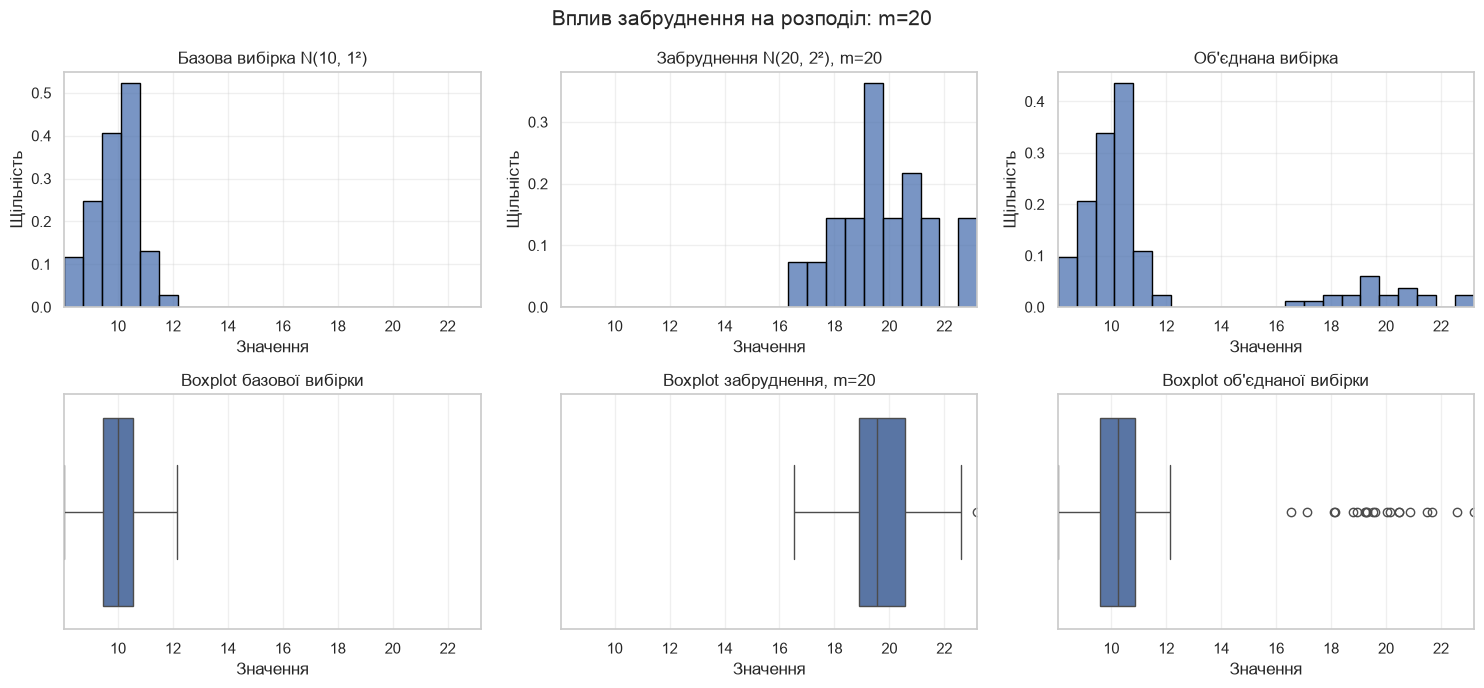

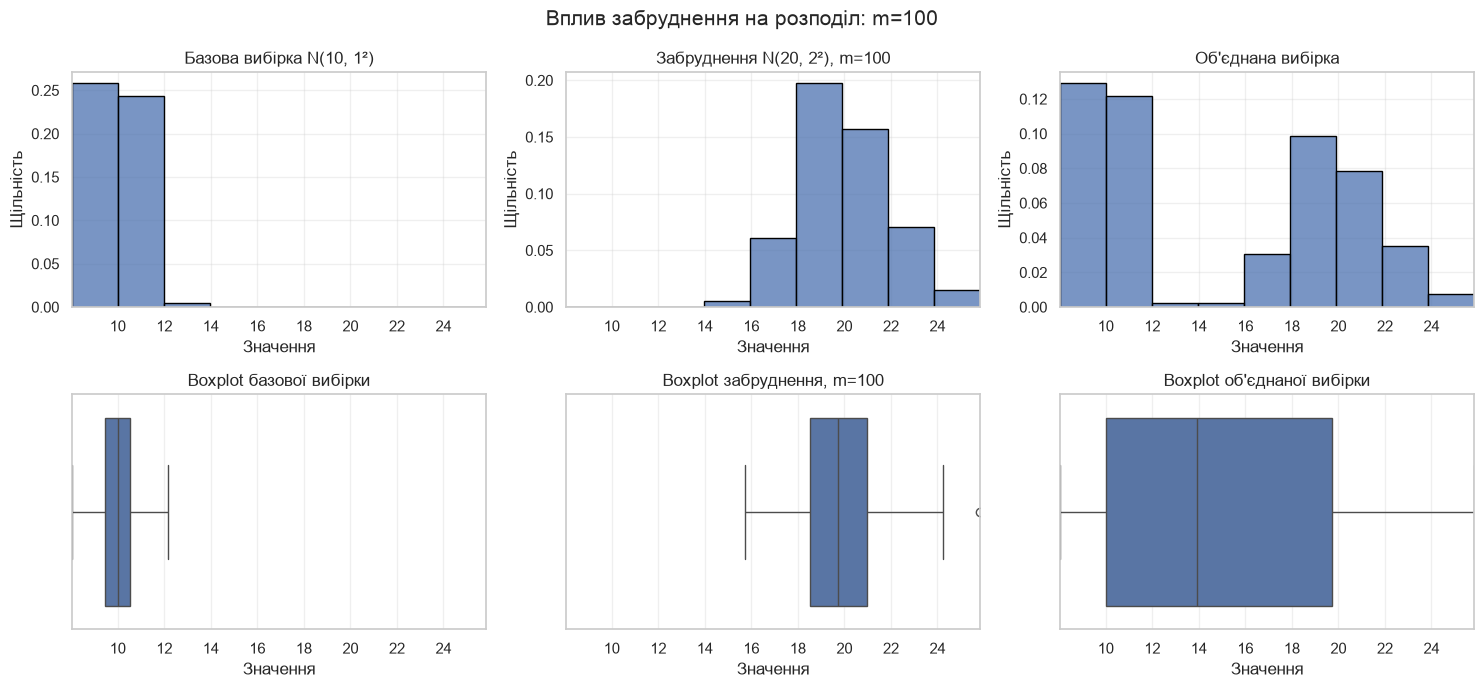

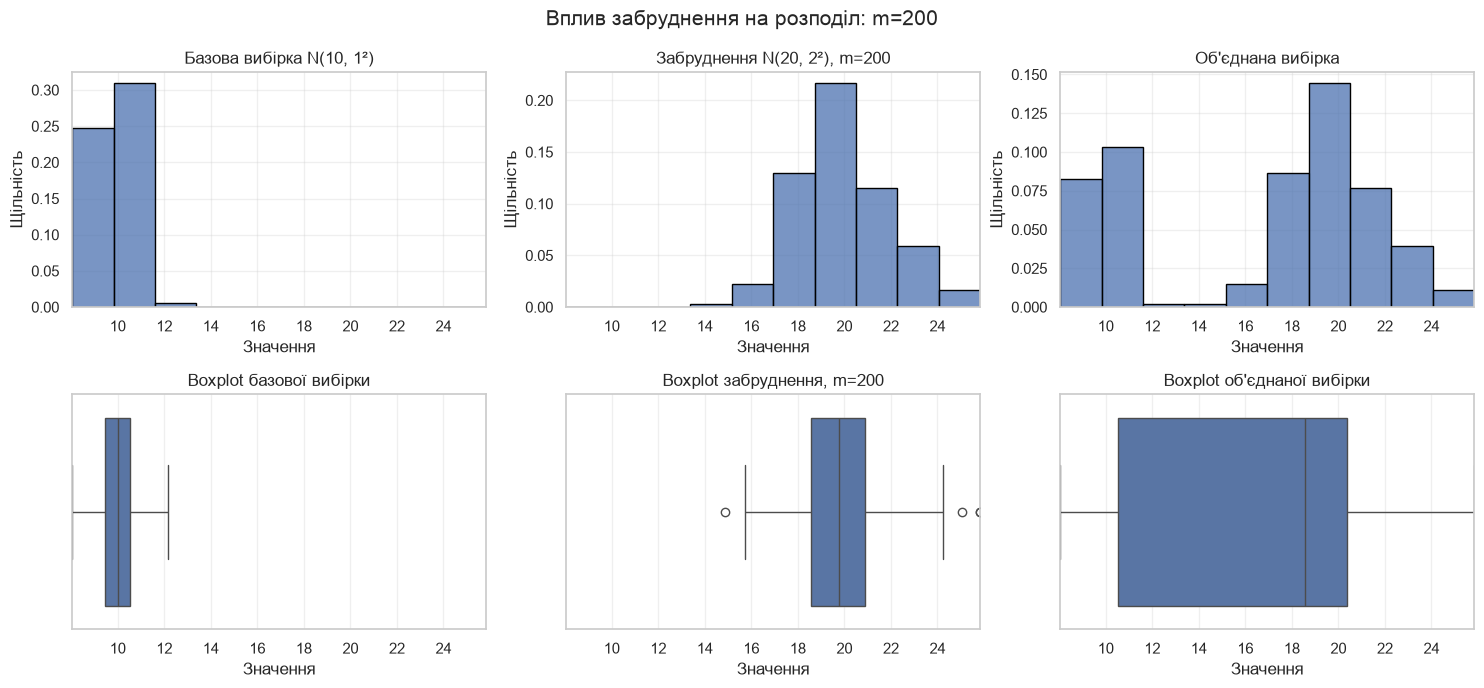

In [3]:
# Контрастні значення m, які прямо вказані в умові
contrast_m_values = [20, 100, 200]

for m in contrast_m_values:
    # Беремо перші m спостережень із уже згенерованої забруднюючої вибірки
    contamination = contamination_sample[:m]

    # Об'єднуємо базову та забруднюючу вибірки
    combined_sample = np.concatenate([
        base_sample,
        contamination
    ])

    # Використовуємо однакові межі інтервалів для всіх трьох гістограм,
    # щоб їх можна було коректно порівнювати між собою.
    common_bin_edges = np.histogram_bin_edges(
        combined_sample,
        bins="auto"
    )

    # Спільні межі осі X для всіх графіків
    x_min = combined_sample.min()
    x_max = combined_sample.max()

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 7)
    )

    # --- Гістограма базової вибірки ---
    sns.histplot(
        base_sample,
        bins=common_bin_edges,
        stat="density",
        edgecolor="black",
        ax=axes[0, 0]
    )
    axes[0, 0].set_title("Базова вибірка N(10, 1²)")
    axes[0, 0].set_ylabel("Щільність")
    axes[0, 0].set_xlim(x_min, x_max)
    axes[0, 0].grid(True, alpha=0.3)

    # --- Гістограма забруднюючої вибірки ---
    sns.histplot(
        contamination,
        bins=common_bin_edges,
        stat="density",
        edgecolor="black",
        ax=axes[0, 1]
    )
    axes[0, 1].set_title(f"Забруднення N(20, 2²), m={m}")
    axes[0, 1].set_ylabel("Щільність")
    axes[0, 1].set_xlim(x_min, x_max)
    axes[0, 1].grid(True, alpha=0.3)

    # --- Гістограма об'єднаної вибірки ---
    sns.histplot(
        combined_sample,
        bins=common_bin_edges,
        stat="density",
        edgecolor="black",
        ax=axes[0, 2]
    )
    axes[0, 2].set_title("Об'єднана вибірка")
    axes[0, 2].set_ylabel("Щільність")
    axes[0, 2].set_xlim(x_min, x_max)
    axes[0, 2].grid(True, alpha=0.3)

    # --- Boxplot базової вибірки ---
    sns.boxplot(
        x=base_sample,
        ax=axes[1, 0]
    )
    axes[1, 0].set_title("Boxplot базової вибірки")
    axes[1, 0].set_xlim(x_min, x_max)
    axes[1, 0].grid(True, axis="x", alpha=0.3)

    # --- Boxplot забруднюючої вибірки ---
    sns.boxplot(
        x=contamination,
        ax=axes[1, 1]
    )
    axes[1, 1].set_title(f"Boxplot забруднення, m={m}")
    axes[1, 1].set_xlim(x_min, x_max)
    axes[1, 1].grid(True, axis="x", alpha=0.3)

    # --- Boxplot об'єднаної вибірки ---
    sns.boxplot(
        x=combined_sample,
        ax=axes[1, 2]
    )
    axes[1, 2].set_title("Boxplot об'єднаної вибірки")
    axes[1, 2].set_xlim(x_min, x_max)
    axes[1, 2].grid(True, axis="x", alpha=0.3)

    # Підпис осі X
    for ax in axes.flat:
        ax.set_xlabel("Значення")

    fig.suptitle(
        f"Вплив забруднення на розподіл: m={m}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

### Інтерпретація

Базова вибірка з $N(10,1^2)$ зосереджена біля 10, а забруднююча вибірка з $N(20,2^2)$ — біля 20 і має більший розкид.

При $m=20$ більшість об'єднаної вибірки все ще складають спостереження з базової групи. На гістограмі видно основний пік біля 10 і невелику окрему групу біля 20. На boxplot значення другої групи переважно позначаються як викиди. У цьому випадку це не випадкові помилки, а спостереження з іншої підвибірки.

При $m=100$ обидві групи мають однаковий розмір. На гістограмі добре видно два окремі скупчення біля 10 і 20. Об'єднаний розподіл є неоднорідним і має два виражені піки.

При $m=200$ друга група вже переважає, тому основна частина об'єднаної вибірки зміщується в напрямку значень біля 20. Водночас група біля 10 все ще добре помітна на гістограмі.

Ці графіки показують, що зі збільшенням $m$ змінюється не лише середнє чи медіана, а й сама форма розподілу. Також видно обмеження boxplot: він добре показує положення та розкид, але може приховувати наявність двох окремих груп, яку значно краще видно на гістограмі.

## Частина 3(а). Теоретичне обґрунтування

Нехай $U,V\sim N(0,1)$ — незалежні випадкові величини. Для $\rho\in[-1,1]$ визначте

$$U^*=U,\qquad V^*=\rho U+\sqrt{1-\rho^2}\,V.$$

Математично доведіть, що $\operatorname{Var}(U^*)=\operatorname{Var}(V^*)=1$ та $\operatorname{Corr}(U^*,V^*)=\rho$. Наведіть виведення у текстовій клітинці нижче.


### Відповідь

Нехай $U,V\sim N(0,1)$ — незалежні випадкові величини. Тоді

$$
E[U]=E[V]=0,
\qquad
\operatorname{Var}(U)=\operatorname{Var}(V)=1.
$$

Оскільки $U$ і $V$ незалежні, їхня **коваріація (covariance)** дорівнює нулю:

$$
\operatorname{Cov}(U,V)=0.
$$

Визначимо

$$
U^*=U,
\qquad
V^*=\rho U+\sqrt{1-\rho^2}V,
$$

де $\rho\in[-1,1]$ — задане значення кореляції.

Для $U^*$:

$$
\operatorname{Var}(U^*)=\operatorname{Var}(U)=1.
$$

Для $V^*$ використаємо властивість дисперсії лінійної комбінації:

$$
\operatorname{Var}(aU+bV)
=
a^2\operatorname{Var}(U)
+
b^2\operatorname{Var}(V)
+
2ab\operatorname{Cov}(U,V).
$$

У нашому випадку $a=\rho$, $b=\sqrt{1-\rho^2}$, а $\operatorname{Cov}(U,V)=0$, тому

$$
\operatorname{Var}(V^*)
=
\rho^2\cdot1
+
(1-\rho^2)\cdot1
=
1.
$$

Отже,

$$
\boxed{\operatorname{Var}(U^*)=\operatorname{Var}(V^*)=1}.
$$

Тепер знайдемо кореляцію. За означенням:

$$
\operatorname{Corr}(U^*,V^*)
=
\frac{\operatorname{Cov}(U^*,V^*)}
{\sqrt{\operatorname{Var}(U^*)\operatorname{Var}(V^*)}}.
$$

Оскільки обидві дисперсії дорівнюють 1, достатньо знайти коваріацію:

$$
\operatorname{Cov}(U^*,V^*)
=
\operatorname{Cov}
\left(
U,\rho U+\sqrt{1-\rho^2}V
\right).
$$

Використовуючи лінійність коваріації:

$$
=
\rho\operatorname{Cov}(U,U)
+
\sqrt{1-\rho^2}\operatorname{Cov}(U,V).
$$

При цьому

$$
\operatorname{Cov}(U,U)=\operatorname{Var}(U)=1,
\qquad
\operatorname{Cov}(U,V)=0.
$$

Тому

$$
\operatorname{Cov}(U^*,V^*)=\rho.
$$

Отже,

$$
\boxed{\operatorname{Corr}(U^*,V^*)=\rho}.
$$

Таким чином, ця конструкція дозволяє отримати дві випадкові величини з дисперсіями 1 і наперед заданою кореляцією $\rho$.

## Частина 3(б). Моделювання кореляції

За наведеним алгоритмом згенеруйте дві вибірки обсягом $n=100$ для кожного $\rho$ від $-0.9$ до $0.9$ з кроком $0.2$. Обчисліть вибіркові коефіцієнти кореляції Пірсона $r$ та Спірмена $\rho_{sp}$. Побудуйте графік їх залежності від заданого теоретичного параметра $\rho$ та порівняйте результати двох методів.


In [4]:
# Окремий генератор випадкових чисел для цієї частини,
# щоб результат був відтворюваним і не залежав від інших блоків notebook.
rng_correlation = np.random.default_rng(SEED)

# Розмір кожної вибірки
correlation_sample_size = 100

# Значення теоретичної кореляції rho:
# -0.9, -0.7, ..., 0.7, 0.9
rho_values = np.round(np.arange(-0.9, 1.0, 0.2), 1)

correlation_results = []

for rho in rho_values:
    # Генеруємо дві незалежні стандартні нормальні вибірки
    U = rng_correlation.normal(loc=0, scale=1, size=correlation_sample_size)
    V = rng_correlation.normal(loc=0, scale=1, size=correlation_sample_size)

    # Будуємо нові змінні за формулою з попереднього підпункту
    U_star = U
    V_star = rho * U + np.sqrt(1 - rho**2) * V

    # Вибіркова кореляція Пірсона
    pearson_r = stats.pearsonr(U_star, V_star).statistic

    # Вибіркова кореляція Спірмена
    spearman_rho = stats.spearmanr(U_star, V_star).statistic

    correlation_results.append({
        "Теоретичне ρ": rho,
        "Пірсон": pearson_r,
        "Спірмен": spearman_rho
    })

# Таблиця результатів
correlation_simulation = pd.DataFrame(correlation_results)

display(correlation_simulation.round(3))

,Теоретичне ρ,Пірсон,Спірмен
0,-0.9,-0.840,-0.832
1,-0.7,-0.717,-0.635
2,-0.5,-0.438,-0.455
3,-0.3,-0.392,-0.341
4,-0.1,-0.112,-0.102
5,0.1,-0.120,-0.117
6,0.3,0.270,0.264
7,0.5,0.492,0.466
8,0.7,0.702,0.711
9,0.9,0.899,0.894


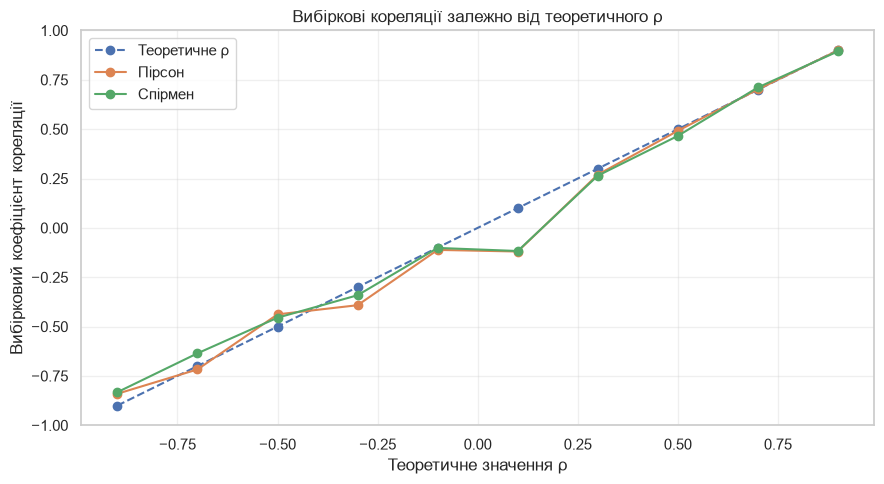

In [5]:
plt.figure(figsize=(9, 5))

# Теоретична кореляція: ідеальна лінія y = rho
plt.plot(
    correlation_simulation["Теоретичне ρ"],
    correlation_simulation["Теоретичне ρ"],
    linestyle="--",
    marker="o",
    label="Теоретичне ρ"
)

# Вибіркова кореляція Пірсона
plt.plot(
    correlation_simulation["Теоретичне ρ"],
    correlation_simulation["Пірсон"],
    marker="o",
    label="Пірсон"
)

# Вибіркова кореляція Спірмена
plt.plot(
    correlation_simulation["Теоретичне ρ"],
    correlation_simulation["Спірмен"],
    marker="o",
    label="Спірмен"
)

plt.title("Вибіркові кореляції залежно від теоретичного ρ")
plt.xlabel("Теоретичне значення ρ")
plt.ylabel("Вибірковий коефіцієнт кореляції")
plt.ylim(-1, 1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Інтерпретація

Вибіркова кореляція Пірсона в цілому добре наближає задане теоретичне значення $\rho$. Чим сильніша за модулем задана кореляція, тим чіткіше вибіркове значення повторює її напрямок і величину.

Точного збігу з $\rho$ немає, оскільки використовується випадкова вибірка лише з $n=100$ спостережень. Наприклад, при $\rho=0.1$ вибіркова кореляція Пірсона дорівнює $-0.120$. Оскільки справжній зв'язок тут дуже слабкий, випадкові коливання вибірки можуть навіть тимчасово змінити його знак.

Кореляції Пірсона та Спірмена в більшості випадків мають близькі значення. Це очікувано, оскільки між $U^*$ та $V^*$ задається лінійний і водночас монотонний зв'язок.

Пірсон безпосередньо оцінює лінійну кореляцію, тому саме його значення повинні наближатися до заданого параметра $\rho$. Спірмен працює з рангами, тому його значення не зобов'язані точно дорівнювати $\rho$, але в цьому експерименті вони поводяться дуже подібно.

Отже, моделювання підтверджує теоретичний результат: заданий параметр $\rho$ визначає напрямок і силу лінійного зв'язку між $U^*$ та $V^*$, а вибіркові коефіцієнти наближають цей зв'язок із певною випадковою похибкою.

## Частина 3(в). Монотонне перетворення

Виконайте нелінійне, але строго монотонне перетворення $V_{\exp}=\exp(V^*)$. Порівняйте коефіцієнти Пірсона та Спірмена для пар $(U^*,V^*)$ і $(U^*,V_{\exp})$, використовуючи ті самі змодельовані спостереження. Візуалізуйте результати та обґрунтуйте економіко-статистичні висновки.


In [6]:
# Створюємо окремий генератор з тим самим SEED.
# Оскільки порядок генерації такий самий, отримаємо ті самі
# змодельовані спостереження, що й у Частині 3(б).
rng_monotonic = np.random.default_rng(SEED)

monotonic_results = []

for rho in rho_values:
    # Ті самі незалежні стандартні нормальні вибірки
    U_mono = rng_monotonic.normal(
        loc=0,
        scale=1,
        size=correlation_sample_size
    )

    V_mono = rng_monotonic.normal(
        loc=0,
        scale=1,
        size=correlation_sample_size
    )

    # Початкові змінні з заданою кореляцією rho
    U_star_mono = U_mono
    V_star_mono = (
        rho * U_mono
        + np.sqrt(1 - rho**2) * V_mono
    )

    # Нелінійне, але строго зростаюче перетворення
    V_exp = np.exp(V_star_mono)

    # Кореляції для початкової пари
    pearson_original = stats.pearsonr(
        U_star_mono,
        V_star_mono
    ).statistic

    spearman_original = stats.spearmanr(
        U_star_mono,
        V_star_mono
    ).statistic

    # Кореляції після exp(V*)
    pearson_exp = stats.pearsonr(
        U_star_mono,
        V_exp
    ).statistic

    spearman_exp = stats.spearmanr(
        U_star_mono,
        V_exp
    ).statistic

    monotonic_results.append({
        "Теоретичне ρ": rho,
        "Пірсон до exp": pearson_original,
        "Пірсон після exp": pearson_exp,
        "Спірмен до exp": spearman_original,
        "Спірмен після exp": spearman_exp
    })

monotonic_comparison = pd.DataFrame(monotonic_results)

display(monotonic_comparison.round(3))

,Теоретичне ρ,Пірсон до exp,Пірсон після exp,Спірмен до exp,Спірмен після exp
0,-0.9,-0.840,-0.777,-0.832,-0.832
1,-0.7,-0.717,-0.624,-0.635,-0.635
2,-0.5,-0.438,-0.356,-0.455,-0.455
3,-0.3,-0.392,-0.387,-0.341,-0.341
4,-0.1,-0.112,-0.006,-0.102,-0.102
5,0.1,-0.120,-0.109,-0.117,-0.117
6,0.3,0.270,0.203,0.264,0.264
7,0.5,0.492,0.409,0.466,0.466
8,0.7,0.702,0.548,0.711,0.711
9,0.9,0.899,0.741,0.894,0.894


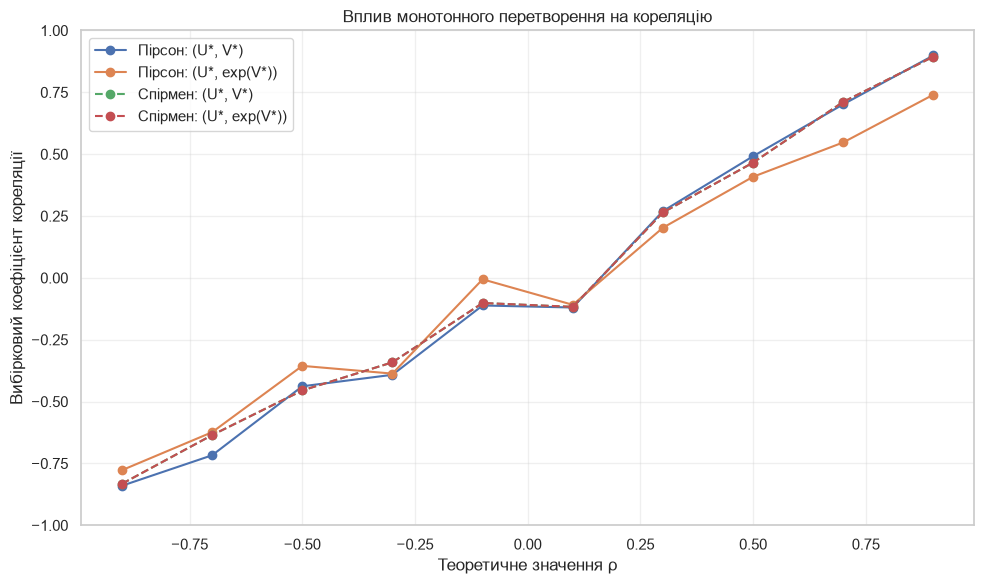

In [7]:
plt.figure(figsize=(10, 6))

plt.plot(
    monotonic_comparison["Теоретичне ρ"],
    monotonic_comparison["Пірсон до exp"],
    marker="o",
    label="Пірсон: (U*, V*)"
)

plt.plot(
    monotonic_comparison["Теоретичне ρ"],
    monotonic_comparison["Пірсон після exp"],
    marker="o",
    label="Пірсон: (U*, exp(V*))"
)

plt.plot(
    monotonic_comparison["Теоретичне ρ"],
    monotonic_comparison["Спірмен до exp"],
    marker="o",
    linestyle="--",
    label="Спірмен: (U*, V*)"
)

plt.plot(
    monotonic_comparison["Теоретичне ρ"],
    monotonic_comparison["Спірмен після exp"],
    marker="o",
    linestyle="--",
    label="Спірмен: (U*, exp(V*))"
)

plt.title("Вплив монотонного перетворення на кореляцію")
plt.xlabel("Теоретичне значення ρ")
plt.ylabel("Вибірковий коефіцієнт кореляції")
plt.ylim(-1, 1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Інтерпретація

Після перетворення $V_{\exp}=\exp(V^*)$ коефіцієнт Спірмена не змінився для жодного значення $\rho$. Це відбувається тому, що експонента є строго зростаючою функцією: вона змінює самі значення, але не змінює їх порядок. Наприклад, при $\rho=0.9$ кореляція Спірмена до і після перетворення дорівнює **0.894**.

Коефіцієнт Пірсона після експоненційного перетворення змінився. Наприклад, при $\rho=0.9$ він зменшився з **0.899** до **0.741**, а при $\rho=-0.1$ — з **-0.112** до **-0.006**. Причина в тому, що експонента робить залежність нелінійною, а Пірсон вимірює саме силу лінійного зв'язку.

Отже, кореляція Спірмена є стійкою до строго монотонних перетворень, оскільки працює з рангами. Кореляція Пірсона залежить від конкретної форми зв'язку між числовими значеннями і тому може змінюватися після нелінійного перетворення.

З практичної точки зору, якщо між економічними показниками є стабільна тенденція зростання або спадання, але вона не є лінійною, Спірмен може краще відобразити цей зв'язок, ніж Пірсон.